# 🎓 Projet 06 (Niveau L3) : "Visualisation & Dashboards IoT d'une Centrale Énergétique"
# 📖 COURS D'INTRODUCTION : Pourquoi visualiser les données d'une centrale IoT ?
Bienvenue dans ce TP/Exercice guidé ! En tant qu'étudiant en Énergie / Physics & Data Science, tu vas apprendre à transformer des flux de données de capteurs en tableaux de bord industriels décisionnels grâce à la bibliothèque Matplotlib, couplée à NumPy et Pandas.

Dans une centrale intelligente (Smart Grid, parc photovoltaïque, réacteur), des milliers de mesures arrivent chaque seconde. Un tableau de chiffres brut est impossible à interpréter à l'œil nu : la visualisation graphique est l'outil indispensable de l'ingénieur pour détecter les pannes, surveiller le rendement et anticiper les surchauffes en temps réel.

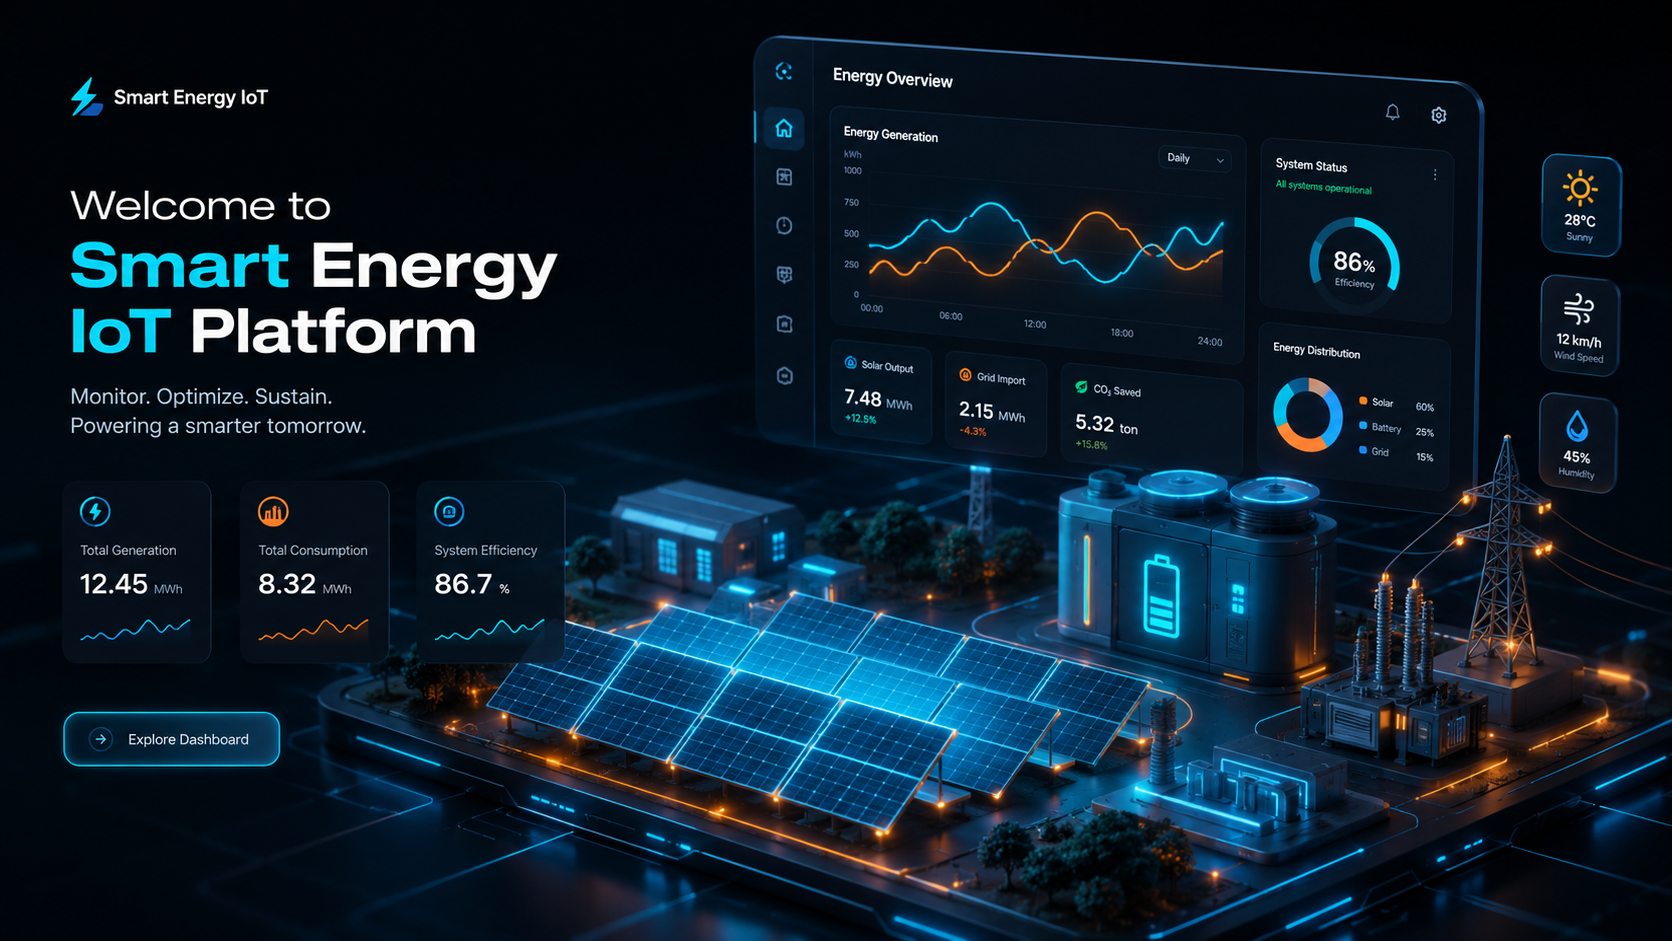

In [1]:
import os
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt 
import numpy as np
import pandas as pd

## 🟢 Niveau 01 : Premier graphique pas à pas et explication des paramètres

Dans ce niveau, nous visualisons la température d'une pièce sur 6 relevés.
Voici le rôle exact de chaque fonction et de chaque paramètre utilisé :

---

### 1. La feuille de travail : `plt.figure()`
* `figsize=(7, 4)` : Définit les dimensions de l'image (Largeur = 7 pouces, Hauteur = 4 pouces).

---

### 2. Le tracé : `plt.plot(x, y, color, linewidth, label)`
* `x` (1er argument, ici `df_temp.index`) : Les données de l'axe horizontal (les heures : '00:00', '04:00'...).
* `y` (2e argument, ici `df_temp.values`) : Les données de l'axe vertical (les températures : 14.5, 13.0...).
* `color="#1f77b4"` : La couleur de la ligne. On peut utiliser un code hexadécimal (`'#1f77b4'`) ou un nom (`'blue'`, `'red'`).
* `linewidth=2` (ou `lw=2`) : L'épaisseur du trait en points (1 = fin, 2 = moyen, 4 = très épais).
* `label="Capteur Salon (°C)"` : Le nom de la courbe. Matplotlib le garde en mémoire pour la légende.

---

### 3. Le texte et les axes : `plt.title()`, `plt.xlabel()`, `plt.ylabel()`
* `plt.title("...", fontweight="bold")` : Le titre principal. `fontweight="bold"` met le texte en gras.
* `plt.xlabel("...")` : L'étiquette sous l'axe horizontal (X).
* `plt.ylabel("...")` : L'étiquette à côté de l'axe vertical (Y), en précisant l'unité (ex: °C).

---

### 4. La lisibilité : `plt.grid()` et `plt.legend()`
* `plt.grid(True, linestyle="--", alpha=0.6)` : Affiche le quadrillage.
  - `True` : Active la grille.
  - `linestyle="--"` : Dessine des lignes en pointillés (au lieu de lignes continues `-`).
  - `alpha=0.6` : Règle la transparence de 0.0 (invisible) à 1.0 (très foncé).
* `plt.legend(loc="upper left")` : Affiche l'encadré de la légende avec le texte du `label`.
  - `loc="upper left"` : Place la légende en haut à gauche (`upper right`, `lower left`, etc.).

---

### 5. Finalisation : `plt.tight_layout()` et `plt.show()`
* `plt.tight_layout()` : Ajuste automatiquement les marges pour éviter que le texte ne déborde.
* `plt.show()` : Affiche le graphique final à l'écran.

In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration : 6 relevés de température dans une journée
# ------------------------------------------------------------------------------
heures = ["00:00", "04:00", "08:00", "12:00", "16:00", "20:00"]
temperatures = [14.5, 13.0, 16.2, 23.5, 25.0, 19.8]

# Création d'une Series Pandas (Index = Heures, Valeurs = Températures)
df_temp = pd.Series(data=temperatures, index=heures, name="Temp_Capteur")


# ------------------------------------------------------------------------------
# QUÊTE 1 : Application pratique étape par étape
# ------------------------------------------------------------------------------
# ### START CODE HERE ###

# ÉTAPE 1 : Créer la figure (7 pouces de large, 4 pouces de haut)
....figure(figsize=(7, 4))

# ÉTAPE 2 : Tracer les données (X = index, Y = valeurs) avec style
plt...(
    df_temp.index,
    df_temp.values,
    color="#1f77b4",
    linewidth=2,
    .. ="Capteur Salon (°C)",
)

# ÉTAPE 3 : Ajouter le titre (en gras) et les noms des axes
plt...("Niveau 01 — Relevé Température IoT", fontweight="bold")
plt.xlabel("Heure de la journée")
plt...("Température (°C)")

# ÉTAPE 4 : Ajouter la grille semi-transparente et la légende en haut à gauche
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper left")

# ÉTAPE 5 : Nettoyer l'affichage et afficher le graphique
plt.tight_layout()
....show()

# ### END CODE HERE ###

# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert len(df_temp) == 6, "La série temporelle doit contenir 6 relevés."
assert df_temp.max() == 25.0, f"Valeur max incorrecte : {df_temp.max()}"
print("🏆 Niveau 01 réussi ! Tous les paramètres sont maîtrisés.")

## 🟢 Niveau 02 : Colorer la zone entre deux courbes (`plt.fill_between`)

Ce niveau enseigne comment visualiser un écart entre deux grandeurs physiques
(ex: Production Solaire vs Consommation Énergétique) pour mettre en évidence un surplus ou un déficit.

---

### 📚 Explication complète de la fonction `plt.fill_between()` :

La fonction s'écrit :
`plt.fill_between(x, y1, y2, where, color, alpha, label)`

* `x` : L'axe horizontal commun aux deux séries (ex: l'index des heures `df.index`).
* `y1` : La première courbe frontière (ex: `df['Production']`).
* `y2` : La seconde courbe frontière (ex: `df['Consommation']`).
* `where` : Une condition logique (True/False). Le remplissage s'effectue UNIQUEMENT là où la condition est vraie.
  - Exemple : `where=(df['Production'] >= df['Consommation'])` colore seulement la zone d'excédent.
* `color` : La couleur de remplissage (ex: `'#2ca02c'` pour vert, ou `'green'`).
* `alpha` : Le degré de transparence de la couleur (entre 0.0 et 1.0).
  - Un `alpha=0.3` permet de voir les lignes de grille sous le remplissage.
* `label` : Le nom de la zone colorée pour l'afficher dans la légende (ex: `'Surplus Injecté'`).

In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration : Profil H24 Production vs Consommation (en Watts)
# ------------------------------------------------------------------------------
heures = pd.date_range(start="2026-08-30 00:00", periods=24, freq="h")
prod = 1000 * np.maximum(0, np.sin(np.pi * np.arange(24) / 24) ** 2)
conso = 300 + 150 * np.cos(np.pi * np.arange(24) / 12) + 100

df_energie = pd.DataFrame(
    {"Production": prod, "Consommation": conso}, index=heures
)


# ------------------------------------------------------------------------------
# QUÊTE 2 : À VOUS DE JOUER ! (Complétez les sections vides)
# ------------------------------------------------------------------------------
# CONSIGNES :
# 1. Préparez une figure de taille (8.5, 4).
# 2. Tracez la courbe 'Production' en vert ('#2ca02c', lw=2) avec son label 'Production (W)'.
# 3. Tracez la courbe 'Consommation' en rouge ('#d62728', lw=2) avec son label 'Consommation (W)'.
# 4. Colorez en vert ('#2ca02c') la zone où Production >= Consommation avec une transparence alpha de 0.3.
# 5. Ajoutez le titre "Niveau 02 — Bilan Énergétique H24", les noms d'axes, la grille '--' et la légende.

# ### START CODE HERE ###

# ÉTAPE 1 : Créer la figure (Largeur: 8.5, Hauteur: 4)
# plt.figure(...)


# ÉTAPE 2 : Tracer les deux courbes (Production et Consommation)
# plt.plot(df_energie.index, df_energie["Production"], ...)
# plt.plot(df_energie.index, df_energie["Consommation"], ...)


# ÉTAPE 3 : Remplir la zone de surplus (Condition : Production >= Consommation)
# plt.fill_between(
#     df_energie.index,
#     df_energie["Production"],
#     df_energie["Consommation"],
#     where=( ... >= ... ),
#     color="#2ca02c",
#     alpha=0.3,
#     label="Surplus Injecté",
# )


# ÉTAPE 4 : Titre, Axes, Grille et Légende
# plt.title(...)
# plt.xlabel(...)
# plt.ylabel(...)
# plt.grid(...)
# plt.legend(...)


# ÉTAPE 5 : Affichage
# plt.tight_layout()
# plt.show()

# ### END CODE HERE ###


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert (
    "Production" in df_energie.columns
), "La colonne Production est manquante."
assert (
    "Consommation" in df_energie.columns
), "La colonne Consommation est manquante."
print("🏆 Niveau 02 prêt à être complété par l'étudiant !")

## 🟡 Niveau 03 : Histogramme, Diagramme en Barres et Côte à Côte

Dans ce niveau, nous découvrons deux nouveaux types de graphiques et comment
placer deux graphiques l'un à côté de l'autre.

---

### 📚 1. Différence fondamentale : Histogramme vs Diagramme en Barres

* **Histogramme (`hist`)** : Mesure la DISTRIBUTION de données CONTINUES.
  - Exemple : Sur 1000 températures mesurées, combien de fois a-t-on eu entre 49°C et 50°C ?
* **Diagramme en Barres (`bar`)** : Compare des CATÉGORIES DISCRÈTES.
  - Exemple : Comparer la production d'énergie entre "Zone Nord", "Zone Sud" et "Zone Ouest".

---

### 📚 2. Créer deux graphiques côte à côte : `plt.subplots(1, 2)`

Pour afficher deux graphiques dans la même fenêtre, on utilise :
`fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))`

* `1, 2` : Signifie 1 ligne et 2 colonnes (deux graphiques côte à côte).
* `fig` : Représente la fenêtre globale.
* `ax1` : Représente le 1er graphique (à gauche).
* `ax2` : Représente le 2e graphique (à droite).

⚠️ **Attention à la syntaxe avec `ax` :**
Quand on utilise `ax1` ou `ax2`, les fonctions changent légèrement de nom :
- `plt.title()`   becomes   `ax1.set_title()`
- `plt.xlabel()`  becomes   `ax1.set_xlabel()`
- `plt.ylabel()`  becomes   `ax1.set_ylabel()`

---

### 📚 3. Explication de TOUS les paramètres :

#### Pour l'Histogramme : `ax1.hist(data, bins, color, edgecolor, alpha)`
* `data` : La série de données numériques continues.
* `bins=20` : Le nombre de "rectangles" (classes d'intervalles) à découper.
* `edgecolor="black"` : Dessine un contour noir autour de chaque barre pour séparer visuellement les rectangles.
* `color="#1f77b4"` : Couleur de remplissage des barres.
* `alpha=0.7` : Transparence.

#### Pour le Diagramme en Barres : `ax2.bar(x, height, color, width)`
* `x` : Les noms des catégories (ex: `['Zone Nord', 'Zone Sud', 'Zone Ouest']`).
* `height` : Les hauteurs respectives de chaque barre (ex: `[450, 720, 310]`).
* `color=['#ff7f0e', '#2ca02c', '#9467bd']` : Une liste de couleurs (une couleur par barre).
* `width=0.5` : La largeur des barres (0.5 = barres affinées, 1.0 = barres collées).
* `ax2.grid(True, axis='y', alpha=0.3)` : `axis='y'` affiche la grille UNIQUEMENT horizontale.

In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration
# ------------------------------------------------------------------------------
np.random.seed(42)

# 1. Données continues : 1000 mesures de température (Bruit gaussien autour de 50°C)
bruit_capteur = pd.Series(np.random.normal(loc=50.0, scale=2.0, size=1000))

# 2. Données catégorisées : Production en kWh par site
df_sites = pd.Series({"Zone Nord": 450, "Zone Sud": 720, "Zone Ouest": 310})


# ------------------------------------------------------------------------------
# QUÊTE 3 : À VOUS DE JOUER ! (Remplissez les lignes commentées)
# ------------------------------------------------------------------------------
# CONSIGNES :
# 1. Créez une figure à 2 panneaux (1 ligne, 2 colonnes) de taille (10, 3.5).
# 2. Sur ax1 (gauche) : Tracez l'histogramme de 'bruit_capteur' avec 25 bins, contour noir et alpha 0.7.
# 3. Sur ax1 : Ajoutez le titre 'Distribution Bruit Capteur (°C)', les labels X ('Température (°C)') et Y ('Fréquence').
# 4. Sur ax2 (droite) : Tracez les barres de 'df_sites' (X = index, Y = values) avec 3 couleurs différentes et width 0.5.
# 5. Sur ax2 : Ajoutez le titre 'Production Solaire par Zone', Y label 'Énergie (kWh)' et une grille sur l'axe Y uniquement.

# ### START CODE HERE ###

# ÉTAPE 1 : Créer la grille à 2 sous-graphiques (ax1 à gauche, ax2 à droite)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))


# ÉTAPE 2 : Graphique de gauche (ax1) - Histogramme
# ax1.hist(
#     bruit_capteur,
#     bins=25,
#     color="#1f77b4",
#     edgecolor="black",
#     alpha=0.7,
# )
# ax1.set_title("Distribution Bruit Capteur (°C)")
# ax1.set_xlabel("Température (°C)")
# ax1.set_ylabel("Fréquence")
# ax1.grid(True, alpha=0.3)


# ÉTAPE 3 : Graphique de droite (ax2) - Diagramme en barres
# ax2.bar(
#     df_sites.index,
#     df_sites.values,
#     color=["#ff7f0e", "#2ca02c", "#9467bd"],
#     width=0.5,
# )
# ax2.set_title("Production Solaire par Zone (kWh)")
# ax2.set_ylabel("Énergie (kWh)")
# ax2.grid(True, axis="y", alpha=0.3)


# ÉTAPE 4 : Ajustement et affichage
# plt.tight_layout()
# plt.show()

# ### END CODE HERE ###


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert len(bruit_capteur) == 1000, "L'échantillon doit contenir 1000 points."
assert len(df_sites) == 3, "Il doit y avoir 3 zones de production."
print("🏆 Niveau 03 prêt à être complété par l'étudiant !")

## 🟡 Niveau 04 : Organiser 4 capteurs IoT dans une matrice 2x2

Dans ce niveau, nous apprenons à créer un vrai tableau de bord (Dashboard)
en disposant 4 métriques différentes sur une grille de 2 lignes et 2 colonnes.

---

### 📚 1. Créer une grille 2x2 : `plt.subplots(2, 2)`

La commande :
`fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 6), sharex=True)`

* `nrows=2, ncols=2` : Crée une matrice de 2 lignes et 2 colonnes (4 sous-graphiques au total).
* `figsize=(10, 6)` : Largeur (10 pouces) et Hauteur (6 pouces) pour l'ensemble du dashboard.
* `sharex=True` : **Partage l'axe temporel X** sur toutes les colonnes.
  - Les dates/heures s'affichent uniquement en bas pour alléger le visuel.
  - Si l'on zoome sur un graphique, tous les autres se synchronisent automatiquement !

---

### 📚 2. Accéder aux 4 quadrants avec la matrice `axes[ligne, colonne]`

`axes` est maintenant une matrice à 2 dimensions (tableau NumPy de 2x2).
Chaque case correspond à un emplacement précis :

  +-----------------------+-----------------------+
  |  `axes[0, 0]`         |  `axes[0, 1]`         |
  |  (Ligne 0, Col 0)     |  (Ligne 0, Col 1)     |
  |  Ex: Température      |  Ex: Pression         |
  +-----------------------+-----------------------+
  |  `axes[1, 0]`         |  `axes[1, 1]`         |
  |  (Ligne 1, Col 0)     |  (Ligne 1, Col 1)     |
  |  Ex: Humidité         |  Ex: Débit            |
  +-----------------------+-----------------------+

---

### 📚 3. Explication détaillée des fonctions et paramètres :

#### A. Méthodes sur un objet `axes[r, c]` :
* `axes[r, c].plot(x, y, color, label)` : Trace la courbe sur le quadrant spécifié.
* `axes[r, c].set_title("Titre", fontsize=10)` : Titre propre à ce quadrant (`fontsize` ajuste la taille du texte).
* `axes[r, c].set_ylabel("Unité")` : Nom de l'axe vertical du quadrant.
* `axes[r, c].grid(True, linestyle="--", alpha=0.5)` : Quadrillage du quadrant.

#### B. Les couleurs prédéfinies de Matplotlib (`tab:...`) :
Au lieu de codes Hexadécimaux, Matplotlib propose une palette standard très lisible :
* `'tab:red'`    : Rouge
* `'tab:blue'`   : Bleu
* `'tab:green'`  : Vert
* `'tab:purple'` : Violet

#### C. Titre global de la figure : `plt.suptitle()`
* `plt.suptitle("Titre Général", fontweight="bold", fontsize=12)` :
  - `suptitle` = "Super Title" : Il se place tout en haut de la figure complète, au-dessus de la grille.

In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration : 50 relevés synthétiques de 4 capteurs IoT
# ------------------------------------------------------------------------------
np.random.seed(42)
temps_idx = pd.date_range("2026-08-30 08:00", periods=50, freq="1min")

df_iot = pd.DataFrame(
    {
        "Temperature": 20 + np.cumsum(np.random.randn(50) * 0.5),
        "Pression": 1013 + np.random.randn(50) * 2,
        "Humidite": 45 + np.sin(np.linspace(0, 5, 50)) * 10,
        "Debut": np.abs(np.random.randn(50) * 5 + 20),
    },
    index=temps_idx,
)


# ------------------------------------------------------------------------------
# QUÊTE 4 : À VOUS DE JOUER ! (Remplissez les lignes commentées)
# ------------------------------------------------------------------------------
# CONSIGNES :
# 1. Créez la grille 2x2 de taille (10, 6) avec sharex=True.
# 2. Quadrant [0, 0] (Haut-Gauche)  : Tracez 'Temperature' (couleur 'tab:red'), titre 'Température (°C)', ylabel '°C'.
# 3. Quadrant [0, 1] (Haut-Droite)  : Tracez 'Pression' (couleur 'tab:blue'), titre 'Pression (hPa)', ylabel 'hPa'.
# 4. Quadrant [1, 0] (Bas-Gauche)   : Tracez 'Humidite' (couleur 'tab:green'), titre 'Humidité (%)', ylabel '%'.
# 5. Quadrant [1, 1] (Bas-Droite)   : Tracez 'Debut' (couleur 'tab:purple'), titre 'Débit (L/min)', ylabel 'L/min'.
# 6. Ajoutez la grille '--' sur chaque quadrant.
# 7. Ajoutez le titre global 'Niveau 04 — Dashboard Multi-Capteurs IoT' avec plt.suptitle().

# ### START CODE HERE ###

# ÉTAPE 1 : Créer la grille 2x2
# fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)


# ÉTAPE 2 : Quadrant [0, 0] - Température (Rouge)
# axes[0, 0].plot(df_iot.index, df_iot["Temperature"], color="tab:red", lw=1.8)
# axes[0, 0].set_title("Température (°C)", fontsize=10)
# axes[0, 0].set_ylabel("°C")
# axes[0, 0].grid(True, linestyle="--", alpha=0.5)


# ÉTAPE 3 : Quadrant [0, 1] - Pression (Bleu)
# axes[0, 1].plot(df_iot.index, df_iot["Pression"], color="tab:blue", lw=1.8)
# axes[0, 1].set_title("Pression (hPa)", fontsize=10)
# axes[0, 1].set_ylabel("hPa")
# axes[0, 1].grid(True, linestyle="--", alpha=0.5)


# ÉTAPE 4 : Quadrant [1, 0] - Humidité (Vert)
# axes[1, 0].plot(df_iot.index, df_iot["Humidite"], color="tab:green", lw=1.8)
# axes[1, 0].set_title("Humidité (%)", fontsize=10)
# axes[1, 0].set_ylabel("%")
# axes[1, 0].grid(True, linestyle="--", alpha=0.5)


# ÉTAPE 5 : Quadrant [1, 1] - Débit (Violet)
# axes[1, 1].plot(df_iot.index, df_iot["Debut"], color="tab:purple", lw=1.8)
# axes[1, 1].set_title("Débit (L/min)", fontsize=10)
# axes[1, 1].set_ylabel("L/min")
# axes[1, 1].grid(True, linestyle="--", alpha=0.5)


# ÉTAPE 6 : Titre global, ajustement et affichage
# plt.suptitle(
#     "Niveau 04 — Dashboard Multi-Capteurs IoT Centrale",
#     fontweight="bold",
#     fontsize=12,
# )
# plt.tight_layout()
# plt.show()

# ### END CODE HERE ###


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert df_iot.shape == (50, 4), "Le DataFrame doit contenir 50 lignes et 4 colonnes."
assert "Temperature" in df_iot.columns, "La colonne Temperature est requise."
print("🏆 Niveau 04 prêt à être complété par l'étudiant !")

## 🟠 Niveau 05 : Superposer deux grandeurs d'échelles différentes sur le même axe X

Dans ce niveau, nous apprenons à résoudre un problème très fréquent en ingénierie :
comment afficher sur un même graphique deux grandeurs physiques mesurées au même moment,
mais avec des unités et des ordres de grandeur complètement différents ?

---

### 📚 1. Le problème des échelles incompatibles

Imaginons que nous mesurions en même temps :
* La **Tension électrique** : autour de **230 Volts**.
* Le **Courant électrique** : autour de **5 Ampères**.

Si on les trace sur le même axe Y, la courbe du courant (5 A) va paraître complètement 
écrasée et plate tout en bas du graphique, car l'axe Y monte jusqu'à 230 V !

---

### 📚 2. La solution : Un second axe Y à droite avec `ax1.twinx()`

La méthode `ax2 = ax1.twinx()` crée un **deuxième axe vertical (Y) sur le côté droit**, 
qui partage exactement le **même axe horizontal (X)** que le premier.

``` Axe Y Gauche (Tension V)                  Axe Y Droit (Courant A)
   [0 V ..... 250 V]                         [0 A ..... 10 A]
           \                                        /
            +--------------------------------------+
            |  Courbe Bleu : Tension (Axe Gauche)  |
            |  Courbe Rouge: Courant (Axe Droit)   |
            +--------------------------------------+
                               |
                   Axe X Commun (Temps / Horodatage) ```

In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration : 100 points de Tension (V) et Courant (A)
# ------------------------------------------------------------------------------
np.random.seed(42)
t_hours = pd.date_range("2026-08-30 08:00", periods=100, freq="15min")

df_elec = pd.DataFrame(
    {
        "Tension_V": 230 + np.sin(np.linspace(0, 10, 100)) * 15 + np.random.randn(100) * 0.5,
        "Courant_A": 5 + np.cos(np.linspace(0, 10, 100)) * 3 + np.random.randn(100) * 0.1,
    },
    index=t_hours,
)


# ------------------------------------------------------------------------------
# QUÊTE 5 : À VOUS DE JOUER ! (Remplissez les lignes commentées)
# ------------------------------------------------------------------------------
# CONSIGNES :
# 1. Créez la figure et le premier axe ax1 de taille (9, 4).
# 2. Sur ax1 (Axe Gauche) :
#    - Tracez 'Tension_V' en bleu ('tab:blue'), épaisseur 2, label 'Tension (V)'.
#    - Mettez l'étiquette 'Horodatage' sur X et 'Tension (V)' en bleu sur Y.
#    - Colorez les graduations Y de ax1 en bleu avec tick_params.
#    - Activez la grille '--'.
# 3. Créez ax2 avec ax1.twinx().
# 4. Sur ax2 (Axe Droit) :
#    - Tracez 'Courant_A' en rouge ('tab:red'), épaisseur 2, ligne en tirets ('--'), label 'Courant (A)'.
#    - Mettez l'étiquette 'Courant (A)' en rouge sur Y.
#    - Colorez les graduations Y de ax2 en rouge avec tick_params.
# 5. Ajoutez le titre "Niveau 05 — Profil Électrique Synchrone (Tension & Courant)".

# ### START CODE HERE ###

# ÉTAPE 1 : Créer la figure et l'axe principal
# fig, ax1 = plt.subplots(figsize=(9, 4))


# ÉTAPE 2 : Configuration de l'axe GAUCHE (ax1) - Tension en BLEU
# color_v = "tab:blue"
# ax1.plot(df_elec.index, df_elec["Tension_V"], color=color_v, lw=2, label="Tension (V)")
# ax1.set_xlabel("Horodatage")
# ax1.set_ylabel("Tension (V)", color=color_v)
# ax1.tick_params(axis="y", labelcolor=color_v)
# ax1.grid(True, linestyle="--", alpha=0.5)


# ÉTAPE 3 : Création du 2e axe Y DROIT partagé
# ax2 = ax1.twinx()


# ÉTAPE 4 : Configuration de l'axe DROIT (ax2) - Courant en ROUGE
# color_a = "tab:red"
# ax2.plot(
#     df_elec.index,
#     df_elec["Courant_A"],
#     color=color_a,
#     lw=2,
#     linestyle="--",
#     label="Courant (A)",
# )
# ax2.set_ylabel("Courant (A)", color=color_a)
# ax2.tick_params(axis="y", labelcolor=color_a)


# ÉTAPE 5 : Titre et Affichage
# plt.title(
#     "Niveau 05 — Profil Électrique Synchrone (Tension & Courant)",
#     fontweight="bold",
# )
# plt.tight_layout()
# plt.show()

# ### END CODE HERE ###


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert "Tension_V" in df_elec.columns, "La colonne Tension_V est manquante."
assert "Courant_A" in df_elec.columns, "La colonne Courant_A est manquante."
assert len(df_elec) == 100, "Le DataFrame doit contenir 100 points."
print("🏆 Niveau 05 prêt à être complété par l'étudiant !")

## 🟠 Niveau 06 : Visualiser une matrice de capteurs en 2D (Heatmap)

Dans ce niveau, nous passons des séries temporelles (1D) à une **carte thermique en deux dimensions (2D)**.
Imaginons une matrice de 8x8 capteurs de température disposés sur une plaque industrielle ou un panneau solaire.

---

### 📚 1. Pourquoi utiliser `plt.imshow()` ?

Alors que `plt.plot()` trace des lignes sur un graphique (X, Y), `plt.imshow()` prend un **tableau à 2 dimensions (Matrice)**
et transforme chaque valeur numérique en une case colorée.
C'est ce qu'on appelle une **Heatmap** (Carte thermique).

---

### 📚 2. Explication détaillée de TOUS les paramètres et fonctions :

#### A. La fonction de carte thermique : `plt.imshow(matrice, cmap, interpolation)`
* `matrice` : Le tableau 2D NumPy ou DataFrame Pandas de dimensions $(N \times M)$ contenant les valeurs numériques (ex: températures de 20°C à 90°C).
* `cmap="inferno"` : La palette de couleurs (Colormap).
  - `'inferno'` : Va du noir/violet (froid) au jaune/blanc (très chaud). Idéal pour la thermographie.
  - Autres palettes populaires : `'viridis'` (bleu-vert-jaune), `'coolwarm'` (bleu-blanc-rouge), `'magma'`.
* `interpolation="nearest"` :
  - `"nearest"` : Affiche des pixels nets et carrés sans flou entre les cases (idéal pour voir chaque capteur individuel).
  - `"bilinear"` ou `"bicubic"` : Lisse les couleurs entre les cases pour faire un dégradé continu.

#### B. La barre de couleur de référence : `plt.colorbar()`
Un graphique en couleurs ne sert à rien si l'on ne sait pas quelle valeur correspond à quelle couleur !
* `cbar = plt.colorbar(heatmap)` : Ajoute l'échelle verticale de couleurs à côté de la carte.
* `cbar.set_label("Température Capteur (°C)")` : Écrit le nom et l'unité à côté de la barre de couleur.

#### C. Nommer les lignes et colonnes : `plt.xticks()` et `plt.yticks()`
Par défaut, Matplotlib affiche les index $0, 1, 2...$ sur les axes. Pour afficher les noms de nos lignes et colonnes :
* `plt.xticks(ticks, labels)` :
  - `ticks=range(8)` : Les positions numériques $0, 1, 2... 7$.
  - `labels=df_grid.columns` : Les noms des colonnes (ex: `'C1'`, `'C2'`, ..., `'C8'`).
* `plt.yticks(ticks, labels)` : Identique pour l'axe vertical Y (ex: `'L1'`, `'L2'`, ..., `'L8'`).

In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration : Grille 8x8 de 64 capteurs de température (°C)
# ------------------------------------------------------------------------------
np.random.seed(10)

# Génération d'une matrice 8x8 avec des températures aléatoires entre 20°C et 90°C
matrice_temp = np.random.uniform(low=20.0, high=90.0, size=(8, 8))

# Conversion en DataFrame Pandas avec noms de lignes (L1 à L8) et colonnes (C1 à C8)
df_grid = pd.DataFrame(
    matrice_temp,
    columns=[f"C{i}" for i in range(1, 9)],
    index=[f"L{i}" for i in range(1, 9)],
)


# ------------------------------------------------------------------------------
# QUÊTE 6 : À VOUS DE JOUER ! (Remplissez les lignes commentées)
# ------------------------------------------------------------------------------
# CONSIGNES :
# 1. Créez une figure carrée de taille (6, 5).
# 2. Affichez la matrice de données avec plt.imshow() :
#    - Utiliser df_grid.values comme matrice.
#    - Palette de couleurs : 'inferno'.
#    - Interpolation : 'nearest'.
# 3. Ajoutez la barre de légende des couleurs avec plt.colorbar() et nommez-la "Température (°C)".
# 4. Ajustez les graduations des axes X et Y avec plt.xticks() et plt.yticks() pour afficher C1..C8 et L1..L8.
# 5. Ajoutez le titre "Niveau 06 — Cartographie Thermique 2D (Champ 8x8)".

# ### START CODE HERE ###

# ÉTAPE 1 : Créer la figure (Format adapté aux cartes 2D)
# plt.figure(figsize=(6, 5))


# ÉTAPE 2 : Générer la carte thermique 2D
# heatmap = plt.imshow(
#     df_grid.values,
#     cmap="inferno",
#     interpolation="nearest",
# )


# ÉTAPE 3 : Ajouter la barre d'échelle des couleurs (Colorbar)
# cbar = plt.colorbar(heatmap)
# cbar.set_label("Température Capteur (°C)")


# ÉTAPE 4 : Nommer les positions des lignes et colonnes
# plt.xticks(ticks=range(8), labels=df_grid.columns)
# plt.yticks(ticks=range(8), labels=df_grid.index)


# ÉTAPE 5 : Titre, ajustement et affichage
# plt.title("Niveau 06 — Cartographie Thermique 2D (Champ 8x8)", fontweight="bold")
# plt.tight_layout()
# plt.show()

# ### END CODE HERE ###


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert df_grid.shape == (8, 8), "La grille de capteurs doit être de taille 8x8."
assert df_grid.values.min() >= 20.0, "Les températures doivent être >= 20°C."
assert df_grid.values.max() <= 90.0, "Les températures doivent être <= 90°C."
print("🏆 Niveau 06 prêt à être complété par l'étudiant !")

## 🔴 Niveau 07 : Personnaliser le thème (Dark Mode) et exporter en HD (300 DPI)

Dans ce niveau, nous apprenons deux compétences indispensables pour les présentations et rapports techniques :
1. Changer l'apparence globale des graphiques avec les **styles prédéfinis** de Matplotlib.
2. Exporter une figure dans un fichier image (PNG, PDF) en **Haute Définition** sans perte de qualité.

---

### 📚 1. Changer le thème global : `plt.style.use()`

Matplotlib propose plusieurs thèmes visuels intégrés. Pour passer en mode "Salle de Contrôle Industrielle" (Fond noir) :
`plt.style.use("dark_background")`

⚠️ **Point important sur les styles :**
* `plt.style.use()` modifie l'apparence de TOUS les graphiques créés après cette ligne.
* Pour revenir au style clair classique à la fin de votre script, utilisez : `plt.style.use("default")`.

---

### 📚 2. Exporter la figure en image HD : `plt.savefig()`

Pour enregistrer votre graphique sur le disque dur au lieu de simplement l'afficher à l'écran :
`plt.savefig("dashboard_dark.png", dpi=300, bbox_inches="tight")`

⚠️ **ATTENTION :** `plt.savefig()` doit OBLIGATOIREMENT être appelé **AVANT** `plt.show()`.
Si vous le placez après `plt.show()`, la figure aura déjà été effacée de la mémoire et vous obtiendrez un fichier image totalement blanc !

---

### 📚 3. Explication détaillée de TOUS les paramètres de `plt.savefig()` :

* `fname` (1er argument) : Le nom du fichier avec son extension (ex: `"dashboard_dark.png"`, `"rapport.pdf"`).
* `dpi=300` : **Dots Per Inch** (Points par pouce = résolution).
  - Écran standard = 72 à 100 DPI.
  - Impression / Rapport de stage / Publication HD = **300 DPI** (image ultra-nette).
* `bbox_inches="tight"` : **Ajuste les bordures de manière serrée**.
  - Empêche que le titre, la légende ou le nom des axes ne soient rognés/coupés sur les bords de l'image enregistrée.
* `facecolor=fig.get_facecolor()` (optionnel) : Conserve la couleur de fond du thème lors de l'export.

In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration : Suivi de décharge d'une Batterie (SOC en %)
# ------------------------------------------------------------------------------
np.random.seed(42)
t_batt = pd.date_range("2026-08-30 10:00", periods=60, freq="1min")

df_batt = pd.DataFrame(
    {"SOC": np.linspace(100, 20, 60) + np.random.randn(60) * 0.5}, index=t_batt
)


# ------------------------------------------------------------------------------
# QUÊTE 7 : À VOUS DE JOUER ! (Remplissez les lignes commentées)
# ------------------------------------------------------------------------------
# CONSIGNES :
# 1. Activez le thème sombre global avec plt.style.use("dark_background").
# 2. Créez une figure de taille (8, 3.5).
# 3. Tracez la courbe de 'SOC' en couleur vert néon ('#00ffcc'), épaisseur 2.5, label 'SOC (%)'.
# 4. Ajoutez le titre "Niveau 07 — Décharge Batterie (Dark Mode)", xlabel 'Horodatage', ylabel 'État de Charge (%)'.
# 5. Activez la grille en pointillés avec couleur grise ('gray') et alpha de 0.4.
# 6. Sauvegardez la figure sous le nom 'dashboard_dark.png' avec dpi=300 et bbox_inches='tight'.
# 7. Affichez la figure avec plt.show(), puis réinitialisez le style standard avec plt.style.use("default").

# ### START CODE HERE ###

# ÉTAPE 1 : Activer le style Sombre
# plt.style.use("dark_background")


# ÉTAPE 2 : Créer la figure (8 pouces de large, 3.5 de haut)
# plt.figure(figsize=(8, 3.5))


# ÉTAPE 3 : Tracer la courbe de décharge avec style néon
# plt.plot(
#     df_batt.index,
#     df_batt["SOC"],
#     color="#00ffcc",
#     linewidth=2.5,
#     label="SOC (%)",
# )


# ÉTAPE 4 : Titre et Axes
# plt.title("Niveau 07 — Décharge Batterie (Dark Mode)", fontweight="bold")
# plt.xlabel("Horodatage")
# plt.ylabel("État de Charge (%)")


# ÉTAPE 5 : Grille personnalisée et Légende
# plt.grid(True, color="gray", linestyle=":", alpha=0.4)
# plt.legend(loc="upper right")
# plt.tight_layout()


# ÉTAPE 6 : Sauvegarder l'image HD AVANT l'affichage (Très important !)
# nom_fichier = "dashboard_dark.png"
# plt.savefig(nom_fichier, dpi=300, bbox_inches="tight")


# ÉTAPE 7 : Afficher puis réinitialiser le thème par défaut
# plt.show()
# plt.style.use("default")

# ### END CODE HERE ###


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert len(df_batt) == 60, "Le DataFrame de batterie doit contenir 60 minutes."
assert os.path.exists("dashboard_dark.png"), "Le fichier image 'dashboard_dark.png' n'a pas été généré."
print("🏆 Niveau 07 prêt à être complété par l'étudiant !")

## 🔴 Niveau 08 : Détecter et pointer automatiquement une anomalie

Ce niveau apprend à rendre un graphique autonome en traçant une ligne de seuil 
et en plaçant une flèche d'annotation automatique sur la valeur maximale enregistrée.

---

### 📚 1. Ligne de seuil horizontale : `ax.axhline(y, color, linestyle, label)`
* `y=70.0` : La position fixe sur l'axe vertical où tracer la ligne d'alerte.
* `color="red"` : La couleur de la ligne de seuil.
* `linestyle="--"` : Utilise des pointillés pour ne pas la confondre avec la courbe de mesures.
* `linewidth=1.5` : Épaisseur de la ligne.

---

### 📚 2. Détection automatique du pic avec Pandas : `.idxmax()` et `.max()`
* `max_val = df.max()` : Extrait la valeur numérique la plus haute (ex: 88.5 °C).
* `max_time = df.idxmax()` : Extrait l'horodatage exact (l'index X) où cette valeur a eu lieu.

---

### 📚 3. Flèche et texte d'annotation : `ax.annotate()`
La méthode `ax.annotate()` relie un texte explicatif à un point précis :

`ax.annotate(text, xy, xytext, arrowprops, fontweight, color)`

* `text` : Le texte à afficher (ex: `"⚠️ SURCHAUFFE: 88.5°C"`).
* `xy=(max_time, max_val)` : Les coordonnées (X, Y) de la **cible** (la pointe de la flèche).
* `xytext=(X_texte, Y_texte)` : Les coordonnées où placer le **texte** (décalé pour la lisibilité).
  - `max_time - pd.Timedelta(minutes=30)` : Décale le texte de 30 min vers la gauche.
  - `max_val - 12` : Descend le texte de 12°C vers le bas.
* `arrowprops=dict(...)` : Dictionnaire de style de la flèche :
  - `facecolor="red"` : Couleur du corps de la flèche.
  - `shrink=0.05` : Espace de sécurité (5%) pour éviter que la pointe ne touche directement le point.
  - `width=2` : Épaisseur du trait de la flèche.
  - `headwidth=8` : Largeur de la pointe de la flèche.

In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration : 100 relevés avec un pic inséré à la 65e minute
# ------------------------------------------------------------------------------
np.random.seed(42)
temps_series = pd.date_range("2026-08-30 08:00", periods=100, freq="1min")
temp_vals = 40 + np.random.randn(100) * 1.5
temp_vals[65] = 88.5  # Anomalie insérée

df_spike = pd.Series(temp_vals, index=temps_series, name="Temp")

# Détection automatique du pic
max_time = df_spike.idxmax()
max_val = df_spike.max()


# ------------------------------------------------------------------------------
# QUÊTE 8 : À VOUS DE JOUER ! (Remplacez les ... par les valeurs requises)
# ------------------------------------------------------------------------------

# 1. Création de la figure
fig, ax = plt.subplots(figsize=(8.5, 4))

# 2. Tracé de la courbe de température
ax.plot(
    df_spike.index,
    df_spike.values,
    color="tab:blue",
    linewidth=1.8,
    label="Temp Capteur",
)

# 3. Tracé du seuil d'alerte horizontal à 70.0°C (Remplir les ...)
ax.axhline(
    y=...,  # <--- Remplir la valeur du seuil (70.0)
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Seuil d'Alerte (70°C)",
)

# 4. Annotation du pic de température (Remplir les ...)
ax.annotate(
    text=f"⚠️ SURCHAUFFE: {max_val:.1f}°C",
    xy=(max_time, ...),  # <--- Remplir la coordonnée Y de la cible (max_val)
    xytext=(max_time - pd.Timedelta(minutes=30), max_val - 12),
    arrowprops=dict(
        facecolor="red", shrink=0.05, width=..., headwidth=8
    ),  # <--- Largeur de flèche (2)
    fontweight="bold",
    color="red",
)

# 5. Habillage graphique
ax.set_title(
    "Niveau 08 — Annotation Automatique d'Anomalie Thermique", fontweight="bold"
)
ax.set_xlabel("Horodatage")
ax.set_ylabel("Température (°C)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert max_val == 88.5, "Le pic maximum doit être égal à 88.5°C."
assert max_time == temps_series[65], "L'horodatage du pic est incorrect."
print(
    "🏆 Niveau 08 réussi ! La détection et l'annotation d'anomalies sont maîtrisées."
)


## 🔴 Niveau 09 : Masterclass Layout Asymétrique avec GridSpec

Dans les niveaux précédents, `plt.subplots(2, 2)` créait des grilles parfaitement rigides et égales.
En ingénierie, on souhaite souvent mettre en valeur une courbe principale (sur toute la largeur en haut)
et placer deux analyses secondaires plus petites en dessous.

C'est le rôle de `GridSpec` : découper la figure en régions de proportions personnalisées.

---

### 📚 1. Découper la figure : `fig.add_gridspec()`

`gs = fig.add_gridspec(nrows=2, ncols=2, height_ratios=[2, 1], width_ratios=[1, 1])`

* `nrows=2, ncols=2` : Matrice de départ à 2 lignes et 2 colonnes.
* `height_ratios=[2, 1]` : La Ligne 0 sera **2 fois plus haute** que la Ligne 1.
* `width_ratios=[1, 1]` : Les deux colonnes conservent la même largeur.

---

### 📚 2. Attribuer les emplacements avec le Slicing Python `gs[ligne, colonne]`

On extrait les axes de la grille `gs` avec `fig.add_subplot()` :

* `ax_main = fig.add_subplot(gs[0, :])` :
  - `0` = Première ligne.
  - `:` = **Toutes les colonnes** (Fusionne la colonne gauche et droite pour faire un grand graphique).
* `ax_left = fig.add_subplot(gs[1, 0])` :
  - Ligne 1 (bas), Colonne 0 (gauche).
* `ax_right = fig.add_subplot(gs[1, 1])` :
  - Ligne 1 (bas), Colonne 1 (droite).

In [ ]:

# ------------------------------------------------------------------------------
# Données de démonstration : Supervision d'un Micro-Réseau Électrique
# ------------------------------------------------------------------------------
np.random.seed(42)
heures = pd.date_range("2026-08-30 00:00", periods=100, freq="15min")

puissance_kw = 50 + np.sin(np.linspace(0, 8, 100)) * 30 + np.random.randn(100) * 2
frequence_hz = np.random.normal(loc=50.0, scale=0.15, size=100)
temp_celsius = 25 + puissance_kw * 0.4 + np.random.randn(100) * 3

df_grid = pd.DataFrame(
    {
        "Puissance_kW": puissance_kw,
        "Frequence_Hz": frequence_hz,
        "Temp_C": temp_celsius,
    },
    index=heures,
)


# ------------------------------------------------------------------------------
# QUÊTE 9 : À VOUS DE JOUER ! (Remplacez les ... par les bonnes valeurs)
# ------------------------------------------------------------------------------

# 1. Création de la figure globale
fig = plt.figure(figsize=(10, 6))

# 2. Configuration du GridSpec : 2 lignes, 2 colonnes, Ligne 0 deux fois plus haute
gs = fig.add_gridspec(
    nrows=2, ncols=2, height_ratios=[2, 1]
)  # <--- Remplir la proportion [2, 1]

# 3. Affectation des 3 axes
ax_main = fig.add_subplot(
    gs[0, :]
)  # <--- Fusionner toutes les colonnes de la 1re ligne avec :
ax_left = fig.add_subplot(gs[1, 0])  # Ligne 1, colonne 0
ax_right = fig.add_subplot(gs[1, 1])  # Ligne 1, colonne 1

# 4. Graphique principal (Haut) : Courbe de puissance
ax_main.plot(
    df_grid.index,
    df_grid["Puissance_kW"],
    color="#1f77b4",
    linewidth=2,
    label="Puissance Appelée",
)
ax_main.set_title("Supervision Centrale — Puissance Appelée (kW)", fontweight="bold")
ax_main.set_ylabel("Puissance (kW)")
ax_main.grid(True, linestyle="--", alpha=0.5)

# 5. Graphique secondaire Bas-Gauche : Histogramme de fréquence réseau
ax_left.hist(df_grid["Frequence_Hz"], bins=15, color="#2ca02c", edgecolor="black", alpha=0.7)
ax_left.set_title("Stabilité Fréquence (Hz)", fontsize=10)
ax_left.set_xlabel("Fréquence (Hz)")
ax_left.set_ylabel("Occurrences")
ax_left.grid(True, linestyle="--", alpha=0.4)

# 6. Graphique secondaire Bas-Droite : Nuage de points (Scatter) Température vs Puissance
ax_right.scatter(
    df_grid["Puissance_kW"],
    df_grid["Temp_C"],
    color="#d62728",
    alpha=0.6,
    edgecolors="none",
)
ax_right.set_title("Corrélation Température vs Puissance", fontsize=10)
ax_right.set_xlabel("Puissance (kW)")
ax_right.set_ylabel("Température (°C)")
ax_right.grid(True, linestyle="--", alpha=0.4)

# 7. Ajustement de l'espacement et affichage
plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert len(df_grid) == 100, "Le jeu de données doit contenir 100 enregistrements."
assert "Puissance_kW" in df_grid.columns, "La colonne Puissance_kW est introuvable."
print("🏆 Niveau 09 réussi ! Les layouts complexes GridSpec n'ont plus de secrets.")


## 🔴 Niveau 10 : Le Chef-d'Œuvre — Zoom Incrusté (Inset Axes) et Formatting Avancé

Pour ce dernier niveau, nous réalisons un graphique de niveau publication scientifique/industrielle.
Nous allons ajouter une fenêtre de ZOOM intégrée (Inset Axes) qui agrandit automatiquement 
une zone critique (un micro-pic de transitoire) directement à l'intérieur du graphique principal.

---

### 📚 1. Créer une fenêtre de zoom incrustée : `ax.inset_axes([x, y, w, h])`

`ax_zoom = ax_main.inset_axes([0.55, 0.45, 0.40, 0.45])`

* `[0.55, 0.45, 0.40, 0.45]` : Emplacement en coordonnées RELATIVES (de 0.0 à 1.0) dans le graphique principal :
  - `0.55` : Départ horizontal (à 55% du bord gauche).
  - `0.45` : Départ vertical (à 45% du bas).
  - `0.40` : Largeur de la fenêtre de zoom (40% du graphique).
  - `0.45` : Hauteur de la fenêtre de zoom (45% du graphique).

---

### 📚 2. Cadrer la zone de zoom : `ax_zoom.set_xlim()` et `ax_zoom.set_ylim()`

Une fois la courbe retracée dans `ax_zoom`, on filtre la période et les valeurs à isoler :
* `ax_zoom.set_xlim(t_debut, t_fin)` : Restreint l'axe horizontal aux 20 minutes exactes de l'anomalie.
* `ax_zoom.set_ylim(min_val, max_val)` : Cadre la hauteur sur le sommet du pic.

---

### 📚 3. Reliage automatique : `ax_main.indicate_inset_zoom(ax_zoom)`

C'est la touche finale de Matplotlib :
`ax_main.indicate_inset_zoom(ax_zoom, edgecolor="red")`
* Dessine une boîte rectangulaire autour du pic sur le graphique principal.
* Trace automatiquement des lignes de connexion reliées à la fenêtre de zoom.

---

### 📚 4. Formater les heures proprement : `mdates.DateFormatter()`
* `import matplotlib.dates as mdates`
* `ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))` : Force l'affichage des heures au format propre "14:30" sans charger l'axe X.


In [ ]:
# ------------------------------------------------------------------------------
# Données de démonstration : Signal stable avec micro-anomalie transitoire
# ------------------------------------------------------------------------------
np.random.seed(42)
t_index = pd.date_range("2026-08-30 12:00", periods=200, freq="1min")
signal_base = 220 + np.sin(np.linspace(0, 10, 200)) * 2 + np.random.randn(200) * 0.3

# Insertion d'un micro-pic de surtension transitoire (durée: 10 min entre l'index 90 et 100)
signal_base[90:100] += np.array([5, 12, 35, 48, 52, 41, 28, 15, 8, 3])

df_signal = pd.Series(signal_base, index=t_index, name="Tension_V")

# Définition de la fenêtre temporelle du pic pour le zoom
t_zoom_start = t_index[85]
t_zoom_end = t_index[105]


# ------------------------------------------------------------------------------
# QUÊTE 10 : À VOUS DE JOUER ! (Remplacez les ... par les bonnes options)
# ------------------------------------------------------------------------------

# 1. Création de la figure principale
fig, ax_main = plt.subplots(figsize=(10, 5))

# 2. Tracé du signal principal
ax_main.plot(
    df_signal.index,
    df_signal.values,
    color="#1f77b4",
    linewidth=1.5,
    label="Tension Réseau (V)",
)
ax_main.set_title(
    "Niveau 10 — Masterclass : Analyse Transitoire & Zoom Incrusté",
    fontweight="bold",
)
ax_main.set_xlabel("Horodatage")
ax_main.set_ylabel("Tension (V)")
ax_main.grid(True, linestyle="--", alpha=0.5)

# 3. Création de la fenêtre de zoom incrustée (X=55%, Y=45%, L=38%, H=45%)
ax_zoom = ax_main.inset_axes(
    [0.55, 0.45, 0.38, 0.45]
)  # <--- Placer les coordonnées [0.55, 0.45, 0.38, 0.45]

# 4. Tracé du même signal à l'intérieur de la fenêtre de zoom (en rouge)
ax_zoom.plot(df_signal.index, df_signal.values, color="#d62728", linewidth=2)

# 5. Réglage des limites du zoom sur la zone du pic
ax_zoom.set_xlim(t_zoom_start, t_zoom_end)
ax_zoom.set_ylim(215, 280)
ax_zoom.set_title("Zoom Micro-Pic Transitoire", fontsize=9, color="#d62728")
ax_zoom.grid(True, linestyle=":", alpha=0.6)

# 6. Formatting des dates sur l'axe du zoom (Format HH:MM)
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

# 7. Relier visuellement le zoom au graphique principal (Remplir ax_zoom)
ax_main.indicate_inset_zoom(
    ax_zoom, edgecolor="#d62728"
)  # <--- Indiquer l'axe de zoom à relier

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# Tests de validation automatisés
# ------------------------------------------------------------------------------
assert len(df_signal) == 200, "Le signal doit contenir 200 points de mesure."
assert df_signal.max() > 270.0, "Le pic transitoire doit dépasser 270V."
print(
    "🏆 NIVEAU 10 RÉUSSI ! PARCOURS MATPLOTLIB TERMINÉ AVEC SUCCÈS MASTERCLASS !"
)